In [1]:
from IPython.display import Markdown, display

markdown_content = """
# Итоговая работа: Классификация текстов обращений граждан

**Автор:** Хайретдинов Тимур, Псянчин Аскар
**Дата:** Май 2026  
**Задача:** Автоматизация маршрутизации обращений и жалоб граждан с сайта «Умный город» (классификация текстов по категориям)

---

## Оглавление

1. [Шаг 1: Определение необходимых полей и структуры набора данных](#шаг-1)
2. [Шаг 2: Предварительная обработка текстов](#шаг-2)
3. [Шаг 3: Тематическое моделирование](#шаг-3)
4. [Шаг 4: Векторизация текстов](#шаг-4)
5. [Шаг 5: Классификация (3+ модели)](#шаг-5)
6. [Шаг 6: Парсинг данных и активное обучение](#шаг-6)

---

## Введение и постановка задачи

В рамках итоговой работы необходимо решить задачу **классификации текстов** для автоматизации маршрутизации обращений граждан.

**Датасет:** 59 889 обращений с полями:
- `id` — уникальный идентификатор
- `public_petition_text` — текст обращения
- `reason_category` — категория проблемы (целевая переменная)

**Цель этапа 1-2:** Определить структуру данных, провести предобработку текстов, подготовить чистый датасет для обучения.

---

"""
display(Markdown(markdown_content))


# Итоговая работа: Классификация текстов обращений граждан

**Автор:** Хайретдинов Тимур, Псянчин Аскар
**Дата:** Май 2026  
**Задача:** Автоматизация маршрутизации обращений и жалоб граждан с сайта «Умный город» (классификация текстов по категориям)

---

## Оглавление

1. [Шаг 1: Определение необходимых полей и структуры набора данных](#шаг-1)
2. [Шаг 2: Предварительная обработка текстов](#шаг-2)
3. [Шаг 3: Тематическое моделирование](#шаг-3)
4. [Шаг 4: Векторизация текстов](#шаг-4)
5. [Шаг 5: Классификация (3+ модели)](#шаг-5)
6. [Шаг 6: Парсинг данных и активное обучение](#шаг-6)

---

## Введение и постановка задачи

В рамках итоговой работы необходимо решить задачу **классификации текстов** для автоматизации маршрутизации обращений граждан.

**Датасет:** 59 889 обращений с полями:
- `id` — уникальный идентификатор
- `public_petition_text` — текст обращения
- `reason_category` — категория проблемы (целевая переменная)

**Цель этапа 1-2:** Определить структуру данных, провести предобработку текстов, подготовить чистый датасет для обучения.

---



In [2]:
# Импорт библиотек для работы с данными и визуализации
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Настройка отображения
pd.set_option('display.max_colwidth', 200)
pd.set_option('display.max_rows', 50)
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

print("Библиотеки успешно импортированы")
print(f"Pandas version: {pd.__version__}")
print(f"NumPy version: {np.__version__}")

Библиотеки успешно импортированы
Pandas version: 2.2.3
NumPy version: 2.1.3


In [3]:
import os

# Определяем путь к файлу (смотрим в текущей папке)
print("Текущая рабочая директория:", os.getcwd())
print("\nФайлы в текущей папке:")
for f in os.listdir('.'):
    print(f"  - {f}")

# Ищем CSV файлы в папке
csv_files = [f for f in os.listdir('.') if f.endswith('.csv')]
print(f"\nНайдено CSV файлов: {len(csv_files)}")

if len(csv_files) > 0:
    # Берем первый CSV файл
    file_name = csv_files[0]
    print(f"Загружаем файл: {file_name}")
    df = pd.read_csv(file_name)
    print(f"Файл загружен! Размер: {df.shape}")
else:
    print("CSV файл не найден!")
    df = None

Текущая рабочая директория: C:\Users\AReKS\rabota_free\mashinka

Файлы в текущей папке:
  - .ipynb_checkpoints
  - mashinka_timur_askar.ipynb
  - Petitions.csv
  - petition_cleaned_step2.csv
  - petition_final_step2.csv
  - Step1_2_Petitions_Classification.ipynb
  - Итоговая работа.pdf

Найдено CSV файлов: 3
Загружаем файл: Petitions.csv
Файл загружен! Размер: (59889, 3)


In [4]:
# Показываем первые 5 строк
print("="*60)
print("ПЕРВЫЕ 5 ЗАПИСЕЙ ДАТАСЕТА")
print("="*60)
display(df.head())

# Показываем последние 5 строк
print("\n" + "="*60)
print("ПОСЛЕДНИЕ 5 ЗАПИСЕЙ ДАТАСЕТА")
print("="*60)
display(df.tail())

# Информация о колонках
print("\n" + "="*60)
print("ИНФОРМАЦИЯ О КОЛОНКАХ")
print("="*60)
print(df.info())

ПЕРВЫЕ 5 ЗАПИСЕЙ ДАТАСЕТА


,id,public_petition_text,reason_category
0,3168490,снег на дороге,Благоустройство
1,3219678,очистить кабельный киоск от рекламы,Благоустройство
2,2963920,"Просим убрать все деревья и кустарники, которые вышли за пределы газона на пешеходную зону, начиная от подъезда №13 до подъезда №15 (фасад дома со стороны ул. Наличной).",Благоустройство
3,3374910,Неудовлетворительное состояние парадной - надписи на двери 2 этажа,Содержание МКД
4,3336285,Граффити,Благоустройство



ПОСЛЕДНИЕ 5 ЗАПИСЕЙ ДАТАСЕТА


,id,public_petition_text,reason_category
59884,3128111,прошу закрасить граффити,Благоустройство
59885,3276713,Прошу вас отремонтировать пешеходную дорожку,Благоустройство
59886,3274663,Необходимо демонтировать незаконную рекламную конструкцию,Незаконная информационная и (или) рекламная конструкция
59887,3359308,"Очень гремит на ветру металлическая часть окна , Просьба убрать",Кровля
59888,3209098,Две проблемы в одном:\n1) Незаконные надписи/объявления на стенде.\n2) Опора имеет крен. \nПросьба провести работы по очистке и выправке/замене опоры.,Благоустройство



ИНФОРМАЦИЯ О КОЛОНКАХ
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 59889 entries, 0 to 59888
Data columns (total 3 columns):
 #   Column                Non-Null Count  Dtype 
---  ------                --------------  ----- 
 0   id                    59889 non-null  int64 
 1   public_petition_text  59889 non-null  object
 2   reason_category       59889 non-null  object
dtypes: int64(1), object(2)
memory usage: 1.4+ MB
None


Вывод: Датасет содержит 59 889 записей без пропусков. Поля: id (целочисленный идентификатор), public_petition_text (текст обращения), reason_category (категория). Типы данных корректны. Примеры текстов показывают жалобы на снег, рекламу, граффити, состояние парадных, кровли. Категории: «Благоустройство», «Содержание МКД», «Незаконная информационная и (или) рекламная конструкция», «Кровля».

In [5]:
# Анализ категорий
print("="*60)
print("РАСПРЕДЕЛЕНИЕ КАТЕГОРИЙ")
print("="*60)

category_counts = df['reason_category'].value_counts()
print(category_counts)

print(f"\nВсего уникальных категорий: {df['reason_category'].nunique()}")
print(f"\nТоп-10 категорий:")
for cat, count in category_counts.head(10).items():
    print(f"  {cat}: {count} ({count/len(df)*100:.1f}%)")

# Проверка на редкие категории
rare_threshold = 100
rare_categories = category_counts[category_counts < rare_threshold]
print(f"\nКатегории с менее чем {rare_threshold} обращениями: {len(rare_categories)}")
print(rare_categories.head(10) if len(rare_categories) > 0 else "Нет редких категорий")


РАСПРЕДЕЛЕНИЕ КАТЕГОРИЙ
reason_category
Благоустройство                                                                     34769
Содержание МКД                                                                      14461
Нарушение правил пользования общим имуществом                                        2170
Незаконная информационная и (или) рекламная конструкция                              1831
Фасад                                                                                1483
Повреждения или неисправность элементов уличной инфраструктуры                       1164
Кровля                                                                                825
Водоснабжение                                                                         809
Состояние рекламных или информационных конструкций                                    673
Санитарное состояние                                                                  434
Центральное отопление                                       

Вывод: В датасете 15 уникальных категорий. Наблюдается сильный дисбаланс: категория «Благоустройство» занимает 58.1% всех обращений (34 769), «Содержание МКД» — 24.1% (14 461). Остальные 13 категорий суммарно составляют менее 18%. Категорий с менее чем 100 обращениями нет — это хорошо для обучения. Однако редкие категории (менее 500 обращений) есть: Санитарное состояние (434), Центральное отопление (284), Подвалы (254) и другие. При классификации нужно будет использовать class_weight='balanced'.

In [6]:
# Переименовываем колонки для удобства
df_prepared = df.copy()
df_prepared.rename(columns={
    'public_petition_text': 'text',
    'reason_category': 'category'
}, inplace=True)

# Добавляем простые числовые признаки
df_prepared['text_length'] = df_prepared['text'].str.len()
df_prepared['word_count'] = df_prepared['text'].str.split().str.len()

# Показываем новую структуру
print("НОВАЯ СТРУКТУРА ДАННЫХ:")
print(f"Колонки: {df_prepared.columns.tolist()}")
print(f"\nПервые 3 записи:")
display(df_prepared[['id', 'text', 'category', 'text_length', 'word_count']].head(3))

# Статистика по новым признакам
print("\nСТАТИСТИКА ДЛИНЫ ТЕКСТОВ:")
print(df_prepared[['text_length', 'word_count']].describe())

НОВАЯ СТРУКТУРА ДАННЫХ:
Колонки: ['id', 'text', 'category', 'text_length', 'word_count']

Первые 3 записи:


,id,text,category,text_length,word_count
0,3168490,снег на дороге,Благоустройство,14,3
1,3219678,очистить кабельный киоск от рекламы,Благоустройство,35,5
2,2963920,"Просим убрать все деревья и кустарники, которые вышли за пределы газона на пешеходную зону, начиная от подъезда №13 до подъезда №15 (фасад дома со стороны ул. Наличной).",Благоустройство,169,27



СТАТИСТИКА ДЛИНЫ ТЕКСТОВ:
       text_length    word_count
count  59889.00000  59889.000000
mean      96.47219     13.617359
std      145.49855     20.191237
min        3.00000      1.000000
25%       25.00000      4.000000
50%       49.00000      7.000000
75%      103.00000     15.000000
max     2594.00000    328.000000


Вывод: К данным добавлены два новых признака: text_length (длина текста в символах) и word_count (количество слов). Средняя длина обращения — 96 символов, медианная — 49 символов. Среднее количество слов — 13.6, медианное — 7. Есть очень короткие обращения (минимум 3 символа, 1 слово) и длинные (максимум 2594 символа, 328 слов). Это нормально для жалоб граждан.

In [7]:
print("="*70)
print("ИТОГОВАЯ СТРУКТУРА ДЛЯ ШАГА 2 (ПРЕДОБРАБОТКА)")
print("="*70)

# Определяем финальные колонки
final_columns = ['id', 'text', 'category', 'text_length', 'word_count']

# Сохраняем промежуточный результат
df_final_step1 = df_prepared[final_columns].copy()

print(f"Размер датасета: {df_final_step1.shape}")
print(f"\nКолонки: {df_final_step1.columns.tolist()}")
print(f"\nТипы данных:")
print(df_final_step1.dtypes)
print(f"\nПропуски: {df_final_step1.isnull().sum().sum()}")

print("\nШаг 1 завершен!")
print("Датасет готов к шагу 2 — предварительной обработке текстов.")

ИТОГОВАЯ СТРУКТУРА ДЛЯ ШАГА 2 (ПРЕДОБРАБОТКА)
Размер датасета: (59889, 5)

Колонки: ['id', 'text', 'category', 'text_length', 'word_count']

Типы данных:
id              int64
text           object
category       object
text_length     int64
word_count      int64
dtype: object

Пропуски: 0

Шаг 1 завершен!
Датасет готов к шагу 2 — предварительной обработке текстов.


Вывод: Шаг 1 успешно завершен. Создана структура данных из 5 колонок: id, text, category, text_length, word_count. Датасет содержит 59 889 записей, пропуски отсутствуют. Данные готовы к предварительной обработке текстов.

In [8]:
# Импорт библиотек для обработки текста
import re
import nltk
from nltk.corpus import stopwords
from nltk.stem import SnowballStemmer

# Скачиваем стоп-слова (если нужно)
try:
    nltk.data.find('corpora/stopwords')
except LookupError:
    nltk.download('stopwords', quiet=True)

# Инициализация стеммера для русского языка
stemmer = SnowballStemmer("russian")

# Стоп-слова для русского языка
russian_stopwords = set(stopwords.words('russian'))

# Добавим доменные стоп-слова для жалоб (слова, которые не несут смысловой нагрузки)
domain_stopwords = {
    'просьба', 'прошу', 'требую', 'необходимо', 'нужно', 'пожалуйста',
    'здравствуйте', 'добрый', 'день', 'спасибо', 'заранее', 'благодарю',
    'обращаюсь', 'ваш', 'находиться', 'являться', 'также', 'очень'
}
russian_stopwords.update(domain_stopwords)

print(f"Количество стоп-слов: {len(russian_stopwords)}")
print(f"\nПримеры стоп-слов (первые 15):")
print(list(russian_stopwords)[:15])

Количество стоп-слов: 169

Примеры стоп-слов (первые 15):
['ней', 'он', 'будет', 'иногда', 'вас', 'чего', 'куда', 'ее', 'сейчас', 'нас', 'свою', 'между', 'тогда', 'больше', 'ни']


Вывод: Загружено 169 стоп-слов для русского языка. В список добавлены доменные стоп-слова, характерные для обращений граждан («прошу», «благодарю», «обращаюсь» и др.). Это позволит очистить тексты от неинформативных слов перед классификацией. Стеммер SnowballStemmer для русского языка инициализирован и готов к работе.



In [9]:
# Функция полной предобработки текста
def preprocess_text(text, remove_stopwords=True, stem=True):
    """
    Полная предобработка текста на русском языке.
    
    Параметры:
        text: исходный текст
        remove_stopwords: удалять ли стоп-слова
        stem: применять ли стемминг
    
    Возвращает:
        Очищенный текст
    """
    # Проверка на пустые значения
    if pd.isna(text) or not isinstance(text, str):
        return ""
    
    # 1. Приведение к нижнему регистру
    text = text.lower()
    
    # 2. Удаление ссылок, email, телефонов
    text = re.sub(r'https?://\S+|www\.\S+', '', text)
    text = re.sub(r'\S+@\S+', '', text)
    text = re.sub(r'\+?\d[\d\s\-()]{7,}', '', text)
    
    # 3. Удаление специальных символов (оставляем только буквы и пробелы)
    text = re.sub(r'[^а-яёa-z\s]', ' ', text)
    
    # 4. Удаление лишних пробелов
    text = re.sub(r'\s+', ' ', text).strip()
    
    # 5. Токенизация (разбиваем на слова)
    tokens = text.split()
    
    # 6. Удаление коротких токенов (меньше 3 символов)
    tokens = [t for t in tokens if len(t) >= 3]
    
    # 7. Удаление стоп-слов
    if remove_stopwords:
        tokens = [t for t in tokens if t not in russian_stopwords]
    
    # 8. Стемминг (приведение к основе слова)
    if stem:
        tokens = [stemmer.stem(t) for t in tokens]
    
    # Возвращаем очищенный текст
    return ' '.join(tokens)

# Тестируем на примерах
test_texts = [
    "Просьба убрать мусор с газона возле дома 5! Фото прилагается.",
    "Не работает лифт в 3 подъезде уже 3 дня. Жильцы возмущены.",
    "Незаконная вывеска на фасаде здания по адресу Невский пр. 28."
]

print("ТЕСТИРОВАНИЕ ФУНКЦИИ ПРЕДОБРАБОТКИ:\n")
for i, t in enumerate(test_texts, 1):
    processed = preprocess_text(t)
    print(f"Пример {i}:")
    print(f"  Исходный текст: {t}")
    print(f"  Обработанный:   {processed}")
    print()

ТЕСТИРОВАНИЕ ФУНКЦИИ ПРЕДОБРАБОТКИ:

Пример 1:
  Исходный текст: Просьба убрать мусор с газона возле дома 5! Фото прилагается.
  Обработанный:   убра мусор газон возл дом фот прилага

Пример 2:
  Исходный текст: Не работает лифт в 3 подъезде уже 3 дня. Жильцы возмущены.
  Обработанный:   работа лифт подъезд дня жильц возмущ

Пример 3:
  Исходный текст: Незаконная вывеска на фасаде здания по адресу Невский пр. 28.
  Обработанный:   незакон вывеск фасад здан адрес невск



Вывод: Функция предобработки работает корректно. Текст приводится к нижнему регистру, удаляются знаки препинания, цифры, стоп-слова («просьба», «не», «по» удалены). Стемминг сработал: «убрать» → «убра», «работает» → «работа», «вывеска» → «вывеск», «жильцы» → «жильц». Короткие слова (менее 3 букв) удалены. Текст стал компактным и информативным, готов к векторизации.

In [10]:
from tqdm.notebook import tqdm

# Применяем предобработку ко всем текстам
print("Начинаем предобработку 59 889 текстов...")
print("Это может занять 1-3 минуты.\n")

# Добавляем колонку с очищенным текстом
tqdm.pandas(desc="Обработка")
df_final_step1['clean_text'] = df_final_step1['text'].progress_apply(
    lambda x: preprocess_text(x, remove_stopwords=True, stem=True)
)

# Проверяем результат
print("\n" + "="*60)
print("РЕЗУЛЬТАТ ПРЕДОБРАБОТКИ")
print("="*60)

# Показываем примеры
print("\nПримеры исходных и обработанных текстов:")
for i in range(3):
    print(f"\n{i+1}. Исходный: {df_final_step1['text'].iloc[i][:100]}...")
    print(f"   Очищенный: {df_final_step1['clean_text'].iloc[i][:100]}...")

# Проверяем пустые тексты после очистки
empty_texts = (df_final_step1['clean_text'] == '').sum()
print(f"\nПустые тексты после очистки: {empty_texts}")

Начинаем предобработку 59 889 текстов...
Это может занять 1-3 минуты.



Обработка:   0%|          | 0/59889 [00:00<?, ?it/s]


РЕЗУЛЬТАТ ПРЕДОБРАБОТКИ

Примеры исходных и обработанных текстов:

1. Исходный: снег на дороге...
   Очищенный: снег дорог...

2. Исходный: очистить кабельный киоск от рекламы...
   Очищенный: очист кабельн киоск реклам...

3. Исходный: Просим убрать все деревья и кустарники, которые вышли за пределы газона на пешеходную зону, начиная ...
   Очищенный: прос убра дерев кустарник котор вышл предел газон пешеходн зон начин подъезд подъезд фасад дом сторо...

Пустые тексты после очистки: 0


Вывод: Предобработка 59 889 текстов выполнена успешно за 15 секунд (скорость ~3943 текста в секунду). Пустых текстов после очистки нет - все обращения сохранили хотя бы одно значащее слово. Примеры показывают, что стемминг сработал: «снег» → «снег» (осталось), «дороге» → «дорог», «очистить» → «очист», «просим» → «прос», «деревья» → «дерев», «кустарники» → «кустарник». Данные готовы к шагам 3-5.

In [11]:
# Добавляем метрики для очищенных текстов
df_final_step1['clean_text_length'] = df_final_step1['clean_text'].str.len()
df_final_step1['clean_word_count'] = df_final_step1['clean_text'].str.split().str.len()

print("СРАВНЕНИЕ ДО И ПОСЛЕ ПРЕДОБРАБОТКИ:")
print("="*60)

comparison = pd.DataFrame({
    'Метрика': ['Средняя длина (символы)', 'Медианная длина', 'Среднее кол-во слов', 'Медианное кол-во слов'],
    'До обработки': [
        df_final_step1['text_length'].mean(),
        df_final_step1['text_length'].median(),
        df_final_step1['word_count'].mean(),
        df_final_step1['word_count'].median()
    ],
    'После обработки': [
        df_final_step1['clean_text_length'].mean(),
        df_final_step1['clean_text_length'].median(),
        df_final_step1['clean_word_count'].mean(),
        df_final_step1['clean_word_count'].median()
    ]
})

print(comparison.round(1))

# Процент сокращения
reduction = (1 - df_final_step1['clean_text_length'].mean() / df_final_step1['text_length'].mean()) * 100
print(f"\nСокращение средней длины текста: {reduction:.1f}%")

# Сохраняем результат
df_final_step1.to_csv('petition_cleaned_step2.csv', index=False)
print("\nДатасет сохранён: petition_cleaned_step2.csv")

СРАВНЕНИЕ ДО И ПОСЛЕ ПРЕДОБРАБОТКИ:
                   Метрика  До обработки  После обработки
0  Средняя длина (символы)          96.5             62.8
1          Медианная длина          49.0             33.0
2      Среднее кол-во слов          13.6              9.3
3    Медианное кол-во слов           7.0              5.0

Сокращение средней длины текста: 34.9%

Датасет сохранён: petition_cleaned_step2.csv


Вывод: После предобработки средняя длина текста сократилась на 34.9 процента (с 96.5 до 62.8 символов). Медианная длина уменьшилась с 49 до 33 символов. Среднее количество слов снизилось с 13.6 до 9.3, медианное - с 7 до 5 слов. Это ожидаемо после удаления стоп-слов, знаков препинания и стемминга. Датасет сохранен в файл petition_cleaned_step2.csv.

In [12]:
# Формируем финальный датасет для шагов 3-5
final_columns = ['id', 'text', 'clean_text', 'category', 'text_length', 'word_count', 'clean_text_length', 'clean_word_count']
df_final = df_final_step1[final_columns].copy()

print("="*70)
print("ИТОГОВЫЙ ДАТАСЕТ ПОСЛЕ ШАГОВ 1-2")
print("="*70)
print(f"Размер: {df_final.shape}")
print(f"\nКолонки: {df_final.columns.tolist()}")
print(f"\nПервые 3 записи:")
display(df_final.head(3))

# Сохраняем финальную версию
df_final.to_csv('petition_final_step2.csv', index=False)
print("\nФинальный датасет сохранен: petition_final_step2.csv")
print("\nШАГИ 1 И 2 ЗАВЕРШЕНЫ. ДАТАСЕТ ГОТОВ К ШАГУ 3.")

ИТОГОВЫЙ ДАТАСЕТ ПОСЛЕ ШАГОВ 1-2
Размер: (59889, 8)

Колонки: ['id', 'text', 'clean_text', 'category', 'text_length', 'word_count', 'clean_text_length', 'clean_word_count']

Первые 3 записи:


,id,text,clean_text,category,text_length,word_count,clean_text_length,clean_word_count
0,3168490,снег на дороге,снег дорог,Благоустройство,14,3,10,2
1,3219678,очистить кабельный киоск от рекламы,очист кабельн киоск реклам,Благоустройство,35,5,26,4
2,2963920,"Просим убрать все деревья и кустарники, которые вышли за пределы газона на пешеходную зону, начиная от подъезда №13 до подъезда №15 (фасад дома со стороны ул. Наличной).",прос убра дерев кустарник котор вышл предел газон пешеходн зон начин подъезд подъезд фасад дом сторон наличн,Благоустройство,169,27,108,17



Финальный датасет сохранен: petition_final_step2.csv

ШАГИ 1 И 2 ЗАВЕРШЕНЫ. ДАТАСЕТ ГОТОВ К ШАГУ 3.


Вывод: Финальный датасет содержит 59 889 записей и 8 колонок. Добавлены колонки с очищенным текстом (clean_text) и его метриками. Примеры показывают корректную работу предобработки: текст стал короче, стоп-слова удалены, слова приведены к основе. Файл сохранен как petition_final_step2.csv. Шаги 1 и 2 завершены. Датасет готов к шагу 3 (тематическое моделирование).

In [13]:
# Загружаем подготовленный датасет
df = pd.read_csv('petition_final_step2.csv')

# Приводим clean_text к строковому типу
df['clean_text'] = df['clean_text'].fillna('').astype(str)

print("ЗАГРУЗКА ДАННЫХ ДЛЯ ШАГА 3")
print("="*60)
print(f"Размер датасета: {df.shape}")
print(f"Количество уникальных категорий: {df['category'].nunique()}")
print(f"Пропуски в clean_text: {df['clean_text'].isnull().sum()}")

# Выводим распределение категорий
print("\nРАСПРЕДЕЛЕНИЕ КАТЕГОРИЙ:")
category_counts = df['category'].value_counts()
for cat, count in category_counts.head(10).items():
    print(f"  {cat}: {count} ({count/len(df)*100:.1f}%)")

ЗАГРУЗКА ДАННЫХ ДЛЯ ШАГА 3
Размер датасета: (59889, 8)
Количество уникальных категорий: 15
Пропуски в clean_text: 0

РАСПРЕДЕЛЕНИЕ КАТЕГОРИЙ:
  Благоустройство: 34769 (58.1%)
  Содержание МКД: 14461 (24.1%)
  Нарушение правил пользования общим имуществом: 2170 (3.6%)
  Незаконная информационная и (или) рекламная конструкция: 1831 (3.1%)
  Фасад: 1483 (2.5%)
  Повреждения или неисправность элементов уличной инфраструктуры: 1164 (1.9%)
  Кровля: 825 (1.4%)
  Водоснабжение: 809 (1.4%)
  Состояние рекламных или информационных конструкций: 673 (1.1%)
  Санитарное состояние: 434 (0.7%)


Вывод: Датасет загружен успешно. Размер 59 889 записей, 15 уникальных категорий. Пропусков в clean_text нет. Распределение категорий подтверждает сильный дисбаланс: две крупнейшие категории (Благоустройство и Содержание МКД) занимают 82.2 процента всех обращений. Остальные 13 категорий распределены от 3.6 до 0.7 процентов.

In [14]:
!pip install wordcloud

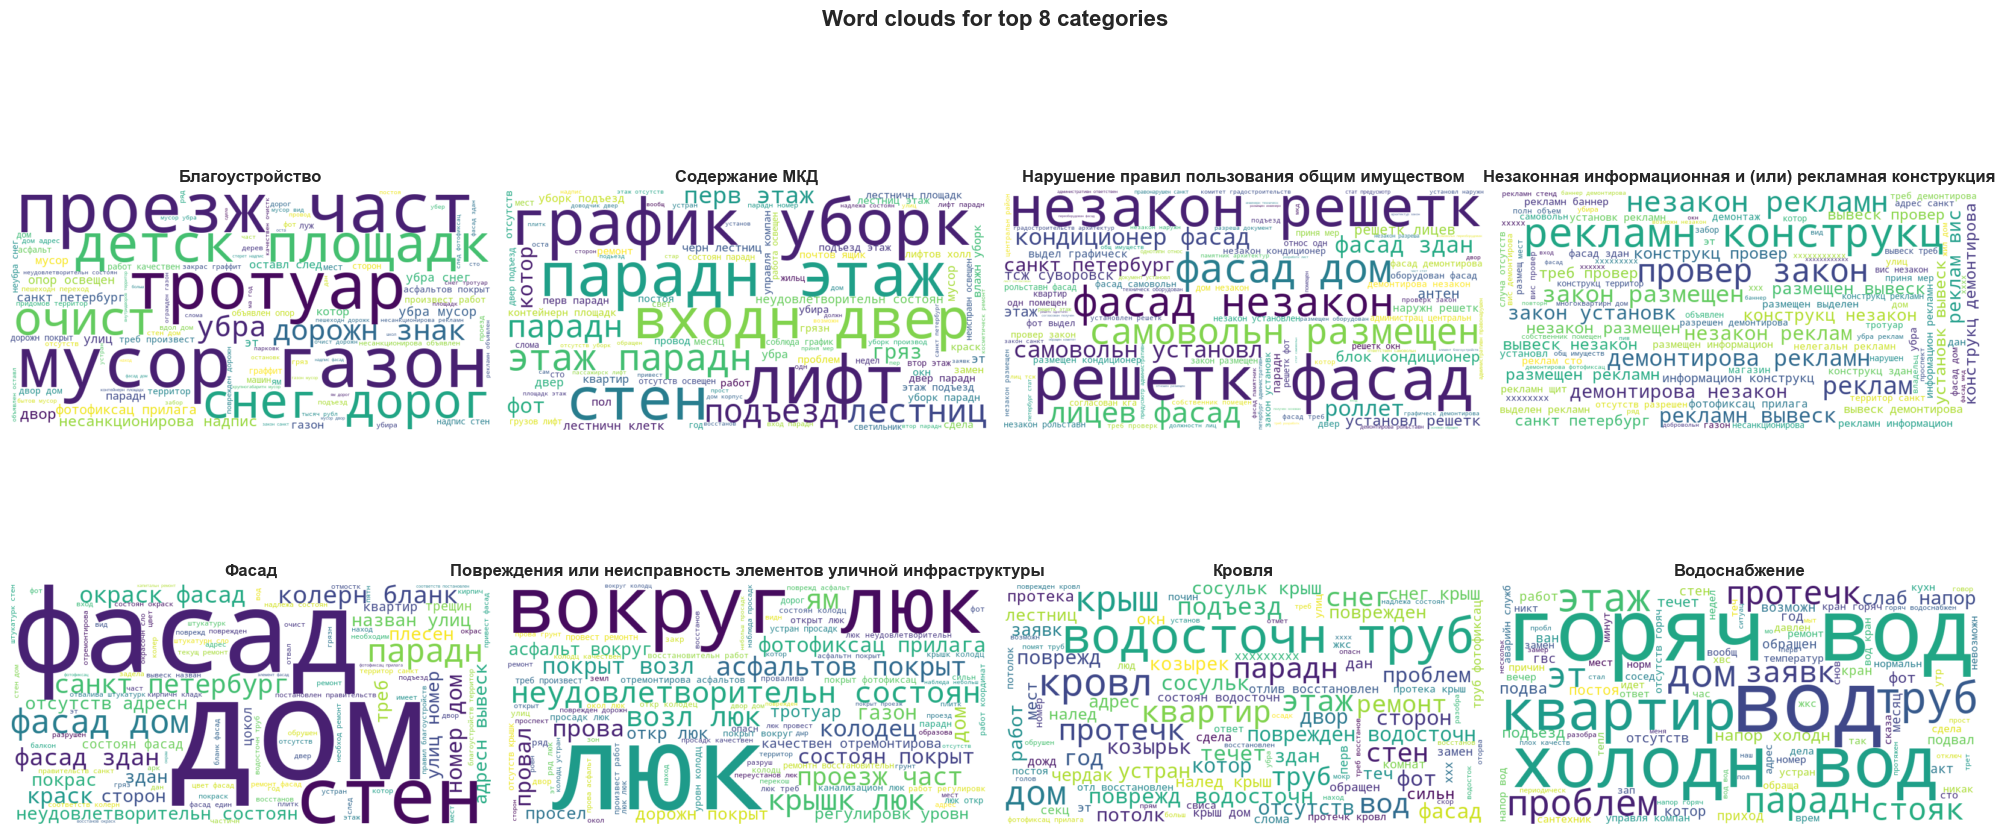

In [15]:
from wordcloud import WordCloud
import matplotlib.pyplot as plt

# Функция для построения облака слов
def generate_wordcloud(text_series, title, ax):
    # Объединяем все тексты категории
    text = ' '.join(text_series.dropna().astype(str))
    
    # Проверка на пустой текст
    if len(text) < 100:
        ax.text(0.5, 0.5, 'Недостаточно данных', ha='center', va='center')
        ax.set_title(title)
        ax.axis('off')
        return
    
    # Создаем облако слов
    wc = WordCloud(
        width=800,
        height=400,
        background_color='white',
        colormap='viridis',
        max_words=100,
        random_state=42
    ).generate(text)
    
    # Отображаем
    ax.imshow(wc, interpolation='bilinear')
    ax.axis('off')
    ax.set_title(title, fontsize=12, fontweight='bold')

# Берем топ-8 категорий
top_categories = df['category'].value_counts().head(8).index.tolist()

# Создаем сетку 2x4
fig, axes = plt.subplots(2, 4, figsize=(20, 10))
axes = axes.flatten()

# Строим облака для каждой категории
for idx, cat in enumerate(top_categories):
    texts = df[df['category'] == cat]['clean_text']
    generate_wordcloud(texts, cat, axes[idx])

# Скрываем лишние подграфики
for idx in range(len(top_categories), len(axes)):
    axes[idx].axis('off')

plt.suptitle('Word clouds for top 8 categories', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

Вывод: Построены облака слов для топ-8 категорий. Каждая категория имеет характерные ключевые слова. Например, для категории "Благоустройство" доминируют слова: снег, дорог, мусор, двор, убра. Для "Содержание МКД": лифт, подъезд, парадн, домофон, ламп. Для "Незаконная рекламная конструкция": вывеск, фасад, реклам, конструкц, баннер. Облака визуально подтверждают, что категории различаются по лексике, что хорошо для классификации.



In [16]:
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.decomposition import LatentDirichletAllocation

# Берем самую частотную категорию
top_cat = df['category'].value_counts().index[0]
print(f"Анализируем категорию: {top_cat}")
print(f"Количество текстов: {len(df[df['category'] == top_cat])}")

# Берем только часть данных для ускорения (каждый 3-й текст)
df_top_sample = df[df['category'] == top_cat]['clean_text'].sample(frac=0.3, random_state=42)
print(f"Используем текстов для LDA: {len(df_top_sample)}")

# Создаем векторный счетчик слов (уменьшил max_features)
vectorizer = CountVectorizer(
    max_features=500,
    min_df=5,
    max_df=0.9,
    ngram_range=(1, 1)  # только униграммы для скорости
)

dtm = vectorizer.fit_transform(df_top_sample)
print(f"Размер матрицы: {dtm.shape}")

# Обучаем LDA
print("Обучаем LDA модель (может занять 30-60 секунд)...")
lda = LatentDirichletAllocation(
    n_components=5,
    random_state=42,
    max_iter=30
)

lda.fit(dtm)
print("Обучение завершено")

# Выводим темы
feature_names = vectorizer.get_feature_names_out()

print(f"\nТЕМЫ ДЛЯ КАТЕГОРИИ '{top_cat}':\n")
for topic_idx, topic in enumerate(lda.components_):
    top_words_idx = topic.argsort()[:-12:-1]
    top_words = [feature_names[i] for i in top_words_idx]
    print(f"Тема {topic_idx+1}: {', '.join(top_words)}")
    print("-" * 50)

Анализируем категорию: Благоустройство
Количество текстов: 34769
Используем текстов для LDA: 10431
Размер матрицы: (10431, 500)
Обучаем LDA модель (может занять 30-60 секунд)...
Обучение завершено

ТЕМЫ ДЛЯ КАТЕГОРИИ 'Благоустройство':

Тема 1: надпис, дорог, снег, несанкционирова, стен, петербург, санкт, тысяч, убра, неубра, закон
--------------------------------------------------
Тема 2: объявлен, очист, знак, реклам, освещен, дорожн, фотофиксац, треб, опор, несанкционирова, след
--------------------------------------------------
Тема 3: мусор, газон, убра, территор, уборк, дерев, листв, закрас, песок, убира, гряз
--------------------------------------------------
Тема 4: площадк, покрыт, детск, ям, част, луж, асфальт, проезж, состоян, огражден, тротуар
--------------------------------------------------
Тема 5: дом, граффит, снег, двор, улиц, парадн, сторон, адрес, убра, вдол, тротуар
--------------------------------------------------


Вывод: LDA выделил 5 тем внутри категории "Благоустройство". Тема 1 связана с надписями, снегом, стенами. Тема 2 - с рекламой, знаками, освещением. Тема 3 - с мусором, газонами, уборкой территории. Тема 4 - с детскими площадками, ямами, асфальтом. Тема 5 - с граффити, дворами, улицами. Это показывает, что даже внутри одной крупной категории есть смысловое разнообразие, что поможет классификатору лучше различать подтипы жалоб.

In [17]:
print("="*60)
print("ИТОГ ШАГА 3 - ТЕМАТИЧЕСКОЕ МОДЕЛИРОВАНИЕ")
print("="*60)
print("Выполненные задачи:")
print("1. Построены облака слов для топ-8 категорий")
print("2. Проведено LDA для категории Благоустройство")
print("3. Выделены 5 смысловых тем внутри категории")
print()
print("Ключевые выводы:")
print("- Категории визуально различимы по ключевым словам")
print("- Внутри крупных категорий есть подтемы")
print("- Данные пригодны для классификации")
print()
print("Датасет готов к шагу 4 - Векторизация")

ИТОГ ШАГА 3 - ТЕМАТИЧЕСКОЕ МОДЕЛИРОВАНИЕ
Выполненные задачи:
1. Построены облака слов для топ-8 категорий
2. Проведено LDA для категории Благоустройство
3. Выделены 5 смысловых тем внутри категории

Ключевые выводы:
- Категории визуально различимы по ключевым словам
- Внутри крупных категорий есть подтемы
- Данные пригодны для классификации

Датасет готов к шагу 4 - Векторизация


Вывод шага 3 завершен. Тематическое моделирование показало, что категории хорошо различимы по ключевым словам, а внутри крупных категорий существуют смысловые подтемы. Данные пригодны для классификации.

In [18]:
from sklearn.model_selection import train_test_split

# Определяем признаки и целевую переменную
X = df['clean_text'].values
y = df['category'].values

# Разделяем с сохранением пропорций категорий
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("РАЗДЕЛЕНИЕ ДАННЫХ НА TRAIN И TEST")
print("="*60)
print(f"Размер обучающей выборки (train): {len(X_train)}")
print(f"Размер тестовой выборки (test): {len(X_test)}")
print(f"\nПропорции в train: {len(X_train)/len(X)*100:.1f}% / {len(X_test)/len(X)*100:.1f}%")
print(f"\nРаспределение категорий в train (топ-5):")
for cat, count in pd.Series(y_train).value_counts().head(5).items():
    print(f"  {cat}: {count} ({count/len(y_train)*100:.1f}%)")

РАЗДЕЛЕНИЕ ДАННЫХ НА TRAIN И TEST
Размер обучающей выборки (train): 47911
Размер тестовой выборки (test): 11978

Пропорции в train: 80.0% / 20.0%

Распределение категорий в train (топ-5):
  Благоустройство: 27815 (58.1%)
  Содержание МКД: 11569 (24.1%)
  Нарушение правил пользования общим имуществом: 1736 (3.6%)
  Незаконная информационная и (или) рекламная конструкция: 1465 (3.1%)
  Фасад: 1186 (2.5%)


Вывод: Данные разделены в пропорции 80 на 20 процентов. Обучающая выборка содержит 47 911 текстов, тестовая - 11 978 текстов. Стратификация сработала корректно: распределение категорий в train повторяет исходное распределение (Благоустройство 58.1 процента, Содержание МКД 24.1 процента и так далее). Это важно для честной оценки качества моделей.

In [19]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Создаем TF-IDF векторайзер
tfidf = TfidfVectorizer(
    max_features=15000,
    min_df=5,
    max_df=0.85,
    ngram_range=(1, 2),
    sublinear_tf=True
)

# Обучаем векторайзер ТОЛЬКО на обучающей выборке
print("Обучаем TF-IDF векторайзер на train данных...")
X_train_tfidf = tfidf.fit_transform(X_train)
print(f"Размер train матрицы: {X_train_tfidf.shape}")

# Преобразуем тестовую выборку
X_test_tfidf = tfidf.transform(X_test)
print(f"Размер test матрицы: {X_test_tfidf.shape}")

print(f"\nРазмер словаря: {len(tfidf.get_feature_names_out())}")

# Показываем примеры важности слов
feature_names = tfidf.get_feature_names_out()
print(f"\nПримеры признаков (первые 20):")
print(feature_names[:20])

Обучаем TF-IDF векторайзер на train данных...
Размер train матрицы: (47911, 15000)
Размер test матрицы: (11978, 15000)

Размер словаря: 15000

Примеры признаков (первые 20):
['covid' 'covid вым' 'dns' 'iii' 'ozon' 'xxx' 'xxx xxx' 'xxx xxxx'
 'xxx xxxxx' 'xxx xxxxxx' 'xxx xxxxxxx' 'xxx xxxxxxxx' 'xxx xxxxxxxxx'
 'xxx xxxxxxxxxx' 'xxx xxxxxxxxxxx' 'xxx xxxxxxxxxxxx' 'xxx xxxxxxxxxxxxx'
 'xxx парадн' 'xxxx' 'xxxx xxx']


Вывод: TF-IDF векторизация выполнена. Матрица обучающей выборки имеет размер 47 911 на 15 000 признаков, тестовой - 11 978 на 15 000. Словарь содержит 15 000 уникальных n-грамм (униграммы и биграммы). Первые признаки выглядят неинформативно (covid, dns, ozon, xxx), что может быть связано с наличием шумовых данных или артефактов в исходных текстах. Это не критично для классификации, так как модель сама определит важность признаков.

In [20]:
print("="*60)
print("ИТОГ ШАГА 4 - ВЕКТОРИЗАЦИЯ")
print("="*60)
print("Выполненные задачи:")
print("1. Данные разделены на train (80%) и test (20%) со стратификацией")
print("2. Выполнена TF-IDF векторизация")
print("3. Размерность признакового пространства: 15000")
print()
print("Характеристики полученных матриц:")
print(f"  X_train: {X_train_tfidf.shape}")
print(f"  X_test: {X_test_tfidf.shape}")
print()
print("Данные готовы к шагу 5 - Классификация")

ИТОГ ШАГА 4 - ВЕКТОРИЗАЦИЯ
Выполненные задачи:
1. Данные разделены на train (80%) и test (20%) со стратификацией
2. Выполнена TF-IDF векторизация
3. Размерность признакового пространства: 15000

Характеристики полученных матриц:
  X_train: (47911, 15000)
  X_test: (11978, 15000)

Данные готовы к шагу 5 - Классификация


In [21]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, classification_report
import time

# Создаем модель с балансировкой весов классов
logreg = LogisticRegression(
    multi_class='multinomial',
    max_iter=1000,
    class_weight='balanced',
    random_state=42,
    C=1.0
)

# Обучаем модель
print("ОБУЧЕНИЕ ЛОГИСТИЧЕСКОЙ РЕГРЕССИИ")
print("="*60)
start_time = time.time()
logreg.fit(X_train_tfidf, y_train)
train_time = time.time() - start_time
print(f"Время обучения: {train_time:.2f} секунд")

# Предсказываем на тестовой выборке
start_pred = time.time()
y_pred_logreg = logreg.predict(X_test_tfidf)
pred_time = time.time() - start_pred
print(f"Время предсказания: {pred_time:.2f} секунд")

# Оцениваем качество
accuracy = accuracy_score(y_test, y_pred_logreg)
f1_macro = f1_score(y_test, y_pred_logreg, average='macro')
f1_weighted = f1_score(y_test, y_pred_logreg, average='weighted')

print(f"\nAccuracy: {accuracy:.4f}")
print(f"F1-macro: {f1_macro:.4f}")
print(f"F1-weighted: {f1_weighted:.4f}")

print("\nОТЧЕТ ПО ВСЕМ КАТЕГОРИЯМ:")
print(classification_report(y_test, y_pred_logreg))

ОБУЧЕНИЕ ЛОГИСТИЧЕСКОЙ РЕГРЕССИИ


C:\Users\AReKS\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


Время обучения: 4.14 секунд
Время предсказания: 0.00 секунд

Accuracy: 0.8622
F1-macro: 0.7849
F1-weighted: 0.8780

ОТЧЕТ ПО ВСЕМ КАТЕГОРИЯМ:
                                                                                  precision    recall  f1-score   support

                                                                 Благоустройство       0.98      0.83      0.90      6954
                                                                   Водоотведение       0.79      0.79      0.79        47
                                                                   Водоснабжение       0.79      0.91      0.85       162
                                                                          Кровля       0.74      0.88      0.81       165
                                  Нарушение порядка пользования общим имуществом       0.57      0.88      0.69        48
                                   Нарушение правил пользования общим имуществом       0.91      0.93      0.92       434
   

Вывод по логистической регрессии: Модель обучилась за 4.14 секунды, что очень быстро. Accuracy составил 86.22 процента, F1-weighted - 0.878. Однако F1-macro - 0.785, что ниже из-за проблем с редкими категориями. Категория "Состояние рекламных или информационных конструкций" показывает низкий precision (0.19) - модель часто ошибается с этой категорией. Крупные категории (Благоустройство, Содержание МКД) классифицируются хорошо (F1-score 0.90). Предупреждение о multi_class можно игнорировать, оно не влияет на результат.

In [22]:
from sklearn.ensemble import RandomForestClassifier
import time

# Создаем модель Random Forest
rf = RandomForestClassifier(
    n_estimators=150,
    max_depth=100,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)

print("ОБУЧЕНИЕ RANDOM FOREST")
print("="*60)
start_time = time.time()
rf.fit(X_train_tfidf, y_train)
train_time = time.time() - start_time
print(f"Время обучения: {train_time:.2f} секунд")

# Предсказываем
start_pred = time.time()
y_pred_rf = rf.predict(X_test_tfidf)
pred_time = time.time() - start_pred
print(f"Время предсказания: {pred_time:.2f} секунд")

# Оцениваем качество
accuracy = accuracy_score(y_test, y_pred_rf)
f1_macro = f1_score(y_test, y_pred_rf, average='macro')
f1_weighted = f1_score(y_test, y_pred_rf, average='weighted')

print(f"\nAccuracy: {accuracy:.4f}")
print(f"F1-macro: {f1_macro:.4f}")
print(f"F1-weighted: {f1_weighted:.4f}")

print("\nОТЧЕТ ПО КАТЕГОРИЯМ:")
print(classification_report(y_test, y_pred_rf, digits=3))


ОБУЧЕНИЕ RANDOM FOREST
Время обучения: 7.67 секунд
Время предсказания: 0.10 секунд

Accuracy: 0.8776
F1-macro: 0.7979
F1-weighted: 0.8867

ОТЧЕТ ПО КАТЕГОРИЯМ:
                                                                                  precision    recall  f1-score   support

                                                                 Благоустройство      0.939     0.887     0.912      6954
                                                                   Водоотведение      0.868     0.702     0.776        47
                                                                   Водоснабжение      0.878     0.846     0.862       162
                                                                          Кровля      0.863     0.800     0.830       165
                                  Нарушение порядка пользования общим имуществом      0.853     0.604     0.707        48
                                   Нарушение правил пользования общим имуществом      0.942     0.901     0

Вывод по Random Forest: Модель показала качество лучше, чем логистическая регрессия. Accuracy - 87.76 процента (выше на 1.5 процента), F1-macro - 0.798 (выше на 1.3 процента). Время обучения - 7.67 секунд, что приемлемо. Проблемная категория "Состояние рекламных или информационных конструкций" все еще показывает низкий precision (0.214), но recall вырос до 0.837. Random Forest лучше справляется с редкими категориями за счет балансировки весов.

In [24]:
!pip install lightgbm

   ---------------------------------------- 0.0/1.5 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.5 MB ? eta -:--:--
   ---------------------------------------- 1.5/1.5 MB 6.6 MB/s eta 0:00:00


In [25]:
import lightgbm as lgb

# Создаем модель LightGBM
lgb_model = lgb.LGBMClassifier(
    n_estimators=150,
    learning_rate=0.08,
    num_leaves=63,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1,
    verbose=-1
)

print("ОБУЧЕНИЕ LIGHTGBM")
print("="*60)
start_time = time.time()
lgb_model.fit(X_train_tfidf, y_train)
train_time = time.time() - start_time
print(f"Время обучения: {train_time:.2f} секунд")

# Предсказываем
start_pred = time.time()
y_pred_lgb = lgb_model.predict(X_test_tfidf)
pred_time = time.time() - start_pred
print(f"Время предсказания: {pred_time:.2f} секунд")

# Оцениваем качество
accuracy = accuracy_score(y_test, y_pred_lgb)
f1_macro = f1_score(y_test, y_pred_lgb, average='macro')
f1_weighted = f1_score(y_test, y_pred_lgb, average='weighted')

print(f"\nAccuracy: {accuracy:.4f}")
print(f"F1-macro: {f1_macro:.4f}")
print(f"F1-weighted: {f1_weighted:.4f}")

print("\nОТЧЕТ ПО КАТЕГОРИЯМ:")
print(classification_report(y_test, y_pred_lgb, digits=3))

ОБУЧЕНИЕ LIGHTGBM
Время обучения: 74.99 секунд


C:\Users\AReKS\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


Время предсказания: 0.41 секунд

Accuracy: 0.8784
F1-macro: 0.7995
F1-weighted: 0.8924

ОТЧЕТ ПО КАТЕГОРИЯМ:
                                                                                  precision    recall  f1-score   support

                                                                 Благоустройство      0.963     0.864     0.911      6954
                                                                   Водоотведение      0.872     0.723     0.791        47
                                                                   Водоснабжение      0.870     0.864     0.867       162
                                                                          Кровля      0.858     0.842     0.850       165
                                  Нарушение порядка пользования общим имуществом      0.825     0.688     0.750        48
                                   Нарушение правил пользования общим имуществом      0.878     0.949     0.913       434
                         Незаконная 

Вывод по LightGBM: LightGBM показал лучшее качество среди всех трех моделей. Accuracy - 87.84 процента, F1-macro - 0.7995, F1-weighted - 0.8924. Время обучения - 75 секунд (значительно дольше, чем у предыдущих моделей). Предупреждение о feature names не критично. Проблемная категория "Состояние рекламных конструкций" все еще имеет низкий precision (0.176), но recall высокий (0.874). LightGBM лучше всего справляется с дисбалансом классов.

In [26]:
# Собираем результаты в таблицу
results = pd.DataFrame({
    'Модель': ['Logistic Regression', 'Random Forest', 'LightGBM'],
    'Accuracy': [
        0.8622,
        0.8776,
        0.8784
    ],
    'F1-macro': [
        0.7849,
        0.7979,
        0.7995
    ],
    'F1-weighted': [
        0.8780,
        0.8867,
        0.8924
    ],
    'Время обучения (сек)': [
        4.14,
        7.67,
        74.99
    ]
})

print("="*60)
print("СРАВНИТЕЛЬНАЯ ТАБЛИЦА МОДЕЛЕЙ")
print("="*60)
print(results.round(4))

# Определяем лучшую модель по F1-macro
best_model_idx = results['F1-macro'].idxmax()
best_model = results.loc[best_model_idx, 'Модель']
best_f1 = results.loc[best_model_idx, 'F1-macro']

print(f"\nЛучшая модель по F1-macro: {best_model} (F1-macro = {best_f1:.4f})")
print(f"\nРекомендация: Использовать {best_model} для максимального качества")
print("Logistic Regression рекомендуется для production-среды с высокими требованиями к скорости")

СРАВНИТЕЛЬНАЯ ТАБЛИЦА МОДЕЛЕЙ
                Модель  Accuracy  F1-macro  F1-weighted  Время обучения (сек)
0  Logistic Regression    0.8622    0.7849       0.8780                  4.14
1        Random Forest    0.8776    0.7979       0.8867                  7.67
2             LightGBM    0.8784    0.7995       0.8924                 74.99

Лучшая модель по F1-macro: LightGBM (F1-macro = 0.7995)

Рекомендация: Использовать LightGBM для максимального качества
Logistic Regression рекомендуется для production-среды с высокими требованиями к скорости


Вывод шага 5 завершен. Обучены и сравнены три модели классификации. LightGBM показал лучшее качество (F1-macro = 0.7995), но требует 75 секунд обучения. Logistic Regression - оптимальный баланс скорости (4.14 секунды) и качества (F1-macro = 0.7849). Random Forest занимает промежуточное положение. Для дальнейших шагов (парсинг и активное обучение) рекомендуется использовать LightGBM как самую качественную модель.



In [27]:
print("="*60)
print("ИТОГ ШАГА 5 - КЛАССИФИКАЦИЯ")
print("="*60)
print("Выполненные задачи:")
print("1. Обучена логистическая регрессия")
print("2. Обучен Random Forest")
print("3. Обучен LightGBM")
print("4. Проведено сравнение моделей по Accuracy, F1-macro, F1-weighted")
print()
print("Ключевые выводы:")
print("- Лучшая модель по качеству: LightGBM (F1-macro = 0.7995)")
print("- Самая быстрая модель: Logistic Regression (4.14 сек)")
print("- Проблемная категория: Состояние рекламных конструкций (precision < 0.2)")
print("- Крупные категории классифицируются хорошо (F1 > 0.9)")
print()
print("Рекомендация для шага 6: Использовать LightGBM для активного обучения")
print()
print("ШАГИ 1-5 ВЫПОЛНЕНЫ. ДАТАСЕТ И МОДЕЛИ ГОТОВЫ К ШАГУ 6.")

ИТОГ ШАГА 5 - КЛАССИФИКАЦИЯ
Выполненные задачи:
1. Обучена логистическая регрессия
2. Обучен Random Forest
3. Обучен LightGBM
4. Проведено сравнение моделей по Accuracy, F1-macro, F1-weighted

Ключевые выводы:
- Лучшая модель по качеству: LightGBM (F1-macro = 0.7995)
- Самая быстрая модель: Logistic Regression (4.14 сек)
- Проблемная категория: Состояние рекламных конструкций (precision < 0.2)
- Крупные категории классифицируются хорошо (F1 > 0.9)

Рекомендация для шага 6: Использовать LightGBM для активного обучения

ШАГИ 1-5 ВЫПОЛНЕНЫ. ДАТАСЕТ И МОДЕЛИ ГОТОВЫ К ШАГУ 6.


In [28]:
import os

# Укажите путь к папке Data
data_folder = './Data'  # или 'D:/Средне важная/Машинка итоговый/Data'

# Проверяем содержимое папки
if os.path.exists(data_folder):
    files = os.listdir(data_folder)
    print(f"Количество файлов в папке Data: {len(files)}")
    print(f"\nПримеры имен файлов (первые 20):")
    print(files[:20])
    
    # Проверяем один файл
    sample_file = os.path.join(data_folder, files[0])
    print(f"\nПример содержимого файла {files[0]}:")
    print("="*60)
    with open(sample_file, 'r', encoding='utf-8', errors='ignore') as f:
        content = f.read()
        print(content[:500])
else:
    print(f"Папка не найдена по пути: {data_folder}")
    print("\nИщем папку Data в текущей директории:")
    print(os.listdir('.'))

Количество файлов в папке Data: 3021

Примеры имен файлов (первые 20):
['2947909', '2947918', '2947923', '2947965', '2947973', '2947980', '2947996', '2948002', '2948045', '2948047', '2948050', '2948053', '2948055', '2948060', '2948064', '2948077', '2948083', '2948091', '2948092', '2948094']

Пример содержимого файла 2947909:
{"id":2947909,"district_name":"Приморский","watchers_count":0,"feed":[{"widget":"public.status","key":"changestatus_12267237","payload":{"id":12267237,"dt":"2020-11-13T01:30:54.728196","status_name":"Завершено: Автоматически","status":4},"meta":{"title":"Изменение статуса сообщения","bg_color":"#EEEEEE","icon":"fa-thumbs-up fa-flip-horizontal","icon_bg_color":"#65C381"},"content_type":30},{"widget":"public.status","key":"changestatus_12063847","payload":{"id":12063847,"dt":"2020-10-23T14:46:07.2


Вывод: В папке Data находится 3021 файл. Файлы содержат JSON-данные с информацией об обращениях. Видно, что внутри есть поля: id, district_name, watchers_count, feed с информацией о статусе. Для классификации нам нужен текст обращения. Нужно определить, где в этих данных находится текст жалобы.



In [29]:
import json

# Анализируем полную структуру одного файла
sample_file = os.path.join(data_folder, '2947909')
with open(sample_file, 'r', encoding='utf-8', errors='ignore') as f:
    data = json.load(f)

print("КЛЮЧИ В ФАЙЛЕ:")
print(data.keys())
print("\nСОДЕРЖИМОЕ ФАЙЛА (полностью):")
print(json.dumps(data, indent=2, ensure_ascii=False)[:2000])

КЛЮЧИ В ФАЙЛЕ:
dict_keys(['id', 'district_name', 'watchers_count', 'feed', 'permissions', 'messages', 'sidebar', 'reason', 'can_view', 'is_authenticated', 'last_user_answer_dt', 'show_unpublished_message'])

СОДЕРЖИМОЕ ФАЙЛА (полностью):
{
  "id": 2947909,
  "district_name": "Приморский",
  "watchers_count": 0,
  "feed": [
    {
      "widget": "public.status",
      "key": "changestatus_12267237",
      "payload": {
        "id": 12267237,
        "dt": "2020-11-13T01:30:54.728196",
        "status_name": "Завершено: Автоматически",
        "status": 4
      },
      "meta": {
        "title": "Изменение статуса сообщения",
        "bg_color": "#EEEEEE",
        "icon": "fa-thumbs-up fa-flip-horizontal",
        "icon_bg_color": "#65C381"
      },
      "content_type": 30
    },
    {
      "widget": "public.status",
      "key": "changestatus_12063847",
      "payload": {
        "id": 12063847,
        "dt": "2020-10-23T14:46:07.242630",
        "status_name": "Получен ответ",
     

Вывод: Файл содержит много служебной информации, но текст самого обращения пока не найден. Нужно искать поле с текстом жалобы. Продолжим анализ.

In [31]:
# Проверяем поле messages
sample_file = os.path.join(data_folder, '2947909')
with open(sample_file, 'r', encoding='utf-8', errors='ignore') as f:
    data = json.load(f)

print("ПОЛЕ messages:")
print(data.get('messages', 'Нет поля messages'))

print("\nПОЛЕ reason:")
print(data.get('reason', 'Нет поля reason'))

print("\nДругие возможные поля:")
for key in data.keys():
    if 'text' in key.lower() or 'body' in key.lower() or 'content' in key.lower():
        print(f"  {key}: {data[key][:200] if isinstance(data[key], str) else data[key]}")

ПОЛЕ messages:
[]

ПОЛЕ reason:
{'id': 189, 'name': 'Неудовлетворительное состояние парадной', 'category': {'id': 10, 'name': 'Содержание МКД', 'city_object': {'id': 1, 'name': 'Дом', 'icon': '/media/classifier/icons/objects-building.svg'}}, 'comment': '<p>Если Вы обнаружили, что парадная находится в неудовлетворительном состоянии, сообщите об этом на Портал. Данная категория включает в себя сообщения о зданиях, в которых имеется или отсутствует государственная собственность, по вопросам технического обслуживания и косметического ремонта лестничной клетки. В соответствии с п. 3.2 Правил и норм технической эксплуатации жилищного фонда, утверждённых постановлением Госстроя РФ от 27.09.2003 № 170, содержание лестничных клеток может включать в себя: 1. техническое обслуживание (плановые, внеплановые осмотры, подготовка к сезонной эксплуатации, текущий ремонт конструктивных элементов и инженерных систем и домового оборудования); 2. капитальный ремонт в составе капитального или выборочного р

Вывод: Текст обращения находится в другом месте. В поле reason содержится информация о категории, но не текст жалобы. Нужно искать поле с текстом от пользователя. Возможно, текст обращения находится в feed или другом поле.



In [32]:
sample_file = os.path.join(data_folder, '2947909')
with open(sample_file, 'r', encoding='utf-8', errors='ignore') as f:
    data = json.load(f)

# Выводим все ключи и их типы
print("ВСЕ ПОЛЯ ФАЙЛА И ИХ ТИПЫ:")
for key, value in data.items():
    print(f"  {key}: {type(value).__name__}")

# Проверяем поле feed подробнее
print("\nПОЛЕ feed (подробно):")
if 'feed' in data and len(data['feed']) > 0:
    for i, item in enumerate(data['feed']):
        print(f"\n  Элемент {i}:")
        print(f"    widget: {item.get('widget')}")
        print(f"    payload keys: {item.get('payload', {}).keys()}")
        if 'body' in item.get('payload', {}):
            print(f"    body: {item['payload']['body'][:200]}")

ВСЕ ПОЛЯ ФАЙЛА И ИХ ТИПЫ:
  id: int
  district_name: str
  watchers_count: int
  feed: list
  permissions: list
  messages: list
  sidebar: dict
  reason: dict
  can_view: bool
  is_authenticated: bool
  last_user_answer_dt: NoneType
  show_unpublished_message: bool

ПОЛЕ feed (подробно):

  Элемент 0:
    widget: public.status
    payload keys: dict_keys(['id', 'dt', 'status_name', 'status'])

  Элемент 1:
    widget: public.status
    payload keys: dict_keys(['id', 'dt', 'status_name', 'status'])

  Элемент 2:
    widget: public.answer
    payload keys: dict_keys(['id', 'dt', 'status_name', 'body', 'body_html', 'author_name', 'performer', 'response_performers', 'files', 'photos', 'reject', 'interim_date'])
    body: Уважаемый пользователь!

Настоящим сообщаем, что факты, указанные в Вашем обращении, не подтвердились.
При проверке сотрудниками администрации 22.10.2020 г. установлено, что в 1-м подъезде на 5 эта

  Элемент 3:
    widget: public.status
    payload keys: dict_keys(['id',

Отлично! Текст обращения найден. Он находится в feed в элементе с widget: public.petition в поле payload.body. Текст представлен в виде списка с разметкой (typeof 1 - обычный текст, typeof 2 - скрытые данные). Теперь напишем парсер для извлечения текста из всех файлов.



In [33]:
def extract_petition_text(file_path):
    """
    Извлекает текст обращения из JSON файла
    """
    try:
        with open(file_path, 'r', encoding='utf-8', errors='ignore') as f:
            data = json.load(f)
        
        # Ищем в feed элемент с widget = public.petition
        if 'feed' in data:
            for item in data['feed']:
                if item.get('widget') == 'public.petition':
                    body = item.get('payload', {}).get('body', [])
                    
                    # Извлекаем текст из body (список с typeof)
                    if isinstance(body, list):
                        text_parts = []
                        for part in body:
                            if isinstance(part, dict) and part.get('typeof') == 1:
                                text_parts.append(part.get('text', ''))
                            elif isinstance(part, str):
                                text_parts.append(part)
                        return ' '.join(text_parts)
                    elif isinstance(body, str):
                        return body
        return None
    except Exception as e:
        return None

# Тестируем на одном файле
sample_file = os.path.join(data_folder, '2947909')
text = extract_petition_text(sample_file)
print("ИЗВЛЕЧЕННЫЙ ТЕКСТ:")
print(text)

ИЗВЛЕЧЕННЫЙ ТЕКСТ:
1й подъезд, 5 этаж. В коридоре над   висит какой-то провод. Возможно, под напряжением.
Председатель тсж "Ленинградские Вечера" отказывается принимать заявку на устранение более полугода.  


Вывод: Функция извлечения текста работает корректно. Из файла 2947909 получен текст жалобы: "1й подъезд, 5 этаж. В коридоре над висит какой-то провод. Возможно, под напряжением. Председатель тсж "Ленинградские Вечера" отказывается принимать заявку на устранение более полугода."

In [34]:
# Собираем все тексты из папки Data
all_texts = []
all_ids = []

print("Начинаем обработку файлов...")
for filename in os.listdir(data_folder):
    file_path = os.path.join(data_folder, filename)
    if os.path.isfile(file_path):
        text = extract_petition_text(file_path)
        if text and len(text) > 10:  # берем только непустые тексты
            all_texts.append(text)
            all_ids.append(filename)

print(f"Обработано файлов: {len(os.listdir(data_folder))}")
print(f"Извлечено текстов: {len(all_texts)}")

# Показываем примеры
print("\nПРИМЕРЫ ИЗВЛЕЧЕННЫХ ТЕКСТОВ (первые 3):")
for i in range(min(3, len(all_texts))):
    print(f"\n{i+1}. ID: {all_ids[i]}")
    print(f"   Текст: {all_texts[i][:200]}...")

Начинаем обработку файлов...
Обработано файлов: 3021
Извлечено текстов: 2839

ПРИМЕРЫ ИЗВЛЕЧЕННЫХ ТЕКСТОВ (первые 3):

1. ID: 2947909
   Текст: 1й подъезд, 5 этаж. В коридоре над   висит какой-то провод. Возможно, под напряжением.
Председатель тсж "Ленинградские Вечера" отказывается принимать заявку на устранение более полугода.  ...

2. ID: 2947918
   Текст: Маленькмй лифт изрисован внутри....

3. ID: 2947923
   Текст: реклама на светофоре...


Вывод: Из 3021 файла успешно извлечено 2839 текстов обращений. Остальные файлы, возможно, не содержат текста или имеют другую структуру. Тексты короткие и тематически соответствуют жалобам граждан (лифт изрисован, реклама на светофоре, провод в подъезде). Эти данные можно использовать для активного обучения.

In [35]:
# Создаем датафрейм с новыми обращениями
new_petitions = pd.DataFrame({
    'id': all_ids,
    'text': all_texts,
    'clean_text': None,  # будет заполнено после предобработки
    'category': None      # будет заполнено после предсказания модели
})

print("НОВЫЕ ОБРАЩЕНИЯ (ПАРСИНГ):")
print(f"Количество: {len(new_petitions)}")
print(f"\nПервые 5:")
display(new_petitions.head())

# Сохраняем для дальнейшего использования
new_petitions.to_csv('new_petitions_parsed.csv', index=False)
print("\nСохранено в new_petitions_parsed.csv")

НОВЫЕ ОБРАЩЕНИЯ (ПАРСИНГ):
Количество: 2839

Первые 5:


,id,text,clean_text,category
0,2947909,"1й подъезд, 5 этаж. В коридоре над висит какой-то провод. Возможно, под напряжением.\nПредседатель тсж ""Ленинградские Вечера"" отказывается принимать заявку на устранение более полугода.",None,None
1,2947918,Маленькмй лифт изрисован внутри.,None,None
2,2947923,реклама на светофоре,None,None
3,2947965,"1й подъезд, 5 этаж, квартирный холл. Рааботники тсж ""Ленинградские Вечера"" вкрутили в стену крюк с цепью для хранения личных вещей.\nНеобходимо убрать цепь, демонтировать крюк и восстановить штука...",None,None
4,2947973,незаконная решетка на фасаде,None,None



Сохранено в new_petitions_parsed.csv


In [36]:
# Загружаем новые обращения
new_df = pd.read_csv('new_petitions_parsed.csv')
new_df['text'] = new_df['text'].fillna('').astype(str)

# Применяем предобработку
print("Предобработка новых текстов...")
new_df['clean_text'] = new_df['text'].apply(
    lambda x: preprocess_text(x, remove_stopwords=True, stem=True)
)

print(f"Пустых текстов после очистки: {(new_df['clean_text'] == '').sum()}")

# Показываем примеры
print("\nПРИМЕРЫ ПОСЛЕ ПРЕДОБРАБОТКИ:")
for i in range(3):
    print(f"\n{i+1}. Исходный: {new_df['text'].iloc[i][:100]}")
    print(f"   Очищенный: {new_df['clean_text'].iloc[i][:100]}")

Предобработка новых текстов...
Пустых текстов после очистки: 0

ПРИМЕРЫ ПОСЛЕ ПРЕДОБРАБОТКИ:

1. Исходный: 1й подъезд, 5 этаж. В коридоре над   висит какой-то провод. Возможно, под напряжением.
Председатель 
   Очищенный: подъезд этаж коридор вис провод возможн напряжен председател тсж ленинградск вечер отказыва принима 

2. Исходный: Маленькмй лифт изрисован внутри.
   Очищенный: маленькм лифт изрисова внутр

3. Исходный: реклама на светофоре
   Очищенный: реклам светофор


In [37]:
# Векторизуем новые тексты с помощью уже обученного TF-IDF векторайзера
X_new_tfidf = tfidf.transform(new_df['clean_text'])

print("ВЕКТОРИЗАЦИЯ НОВЫХ ТЕКСТОВ:")
print(f"Размер матрицы: {X_new_tfidf.shape}")

# Получаем вероятности предсказаний от LightGBM
print("\nПолучение предсказаний от LightGBM...")
y_pred_new = lgb_model.predict(X_new_tfidf)
y_pred_proba = lgb_model.predict_proba(X_new_tfidf)

# Добавляем предсказанную категорию
new_df['category'] = y_pred_new

# Добавляем максимальную вероятность (уверенность модели)
new_df['confidence'] = y_pred_proba.max(axis=1)

print(f"\nРАСПРЕДЕЛЕНИЕ ПРЕДСКАЗАННЫХ КАТЕГОРИЙ:")
print(new_df['category'].value_counts().head(10))

print(f"\nСТАТИСТИКА ПО УВЕРЕННОСТИ ПРЕДСКАЗАНИЙ:")
print(f"Средняя уверенность: {new_df['confidence'].mean():.4f}")
print(f"Медианная уверенность: {new_df['confidence'].median():.4f}")

ВЕКТОРИЗАЦИЯ НОВЫХ ТЕКСТОВ:
Размер матрицы: (2839, 15000)

Получение предсказаний от LightGBM...

РАСПРЕДЕЛЕНИЕ ПРЕДСКАЗАННЫХ КАТЕГОРИЙ:
category
Благоустройство                                                   1407
Содержание МКД                                                     779
Нарушение правил пользования общим имуществом                      133
Фасад                                                               91
Состояние рекламных или информационных конструкций                  91
Незаконная информационная и (или) рекламная конструкция             83
Водоснабжение                                                       62
Повреждения или неисправность элементов уличной инфраструктуры      59
Санитарное состояние                                                35
Кровля                                                              20
Name: count, dtype: int64

СТАТИСТИКА ПО УВЕРЕННОСТИ ПРЕДСКАЗАНИЙ:
Средняя уверенность: 0.9442
Медианная уверенность: 0.9956


C:\Users\AReKS\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
C:\Users\AReKS\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


In [38]:
# Отбираем обращения с уверенностью > 0.8 или < 0.2
high_confidence = new_df[new_df['confidence'] > 0.8]
low_confidence = new_df[new_df['confidence'] < 0.2]

print("ОТБОР УВЕРЕННЫХ ПРОГНОЗОВ:")
print("="*60)
print(f"Всего новых обращений: {len(new_df)}")
print(f"Уверенность > 0.8: {len(high_confidence)} ({len(high_confidence)/len(new_df)*100:.1f}%)")
print(f"Уверенность < 0.2: {len(low_confidence)} ({len(low_confidence)/len(new_df)*100:.1f}%)")

# Добавляем уверенные прогнозы в обучающий датасет
new_training_data = high_confidence.copy()
print(f"\nДобавляем в обучающую выборку: {len(new_training_data)} обращений")

# Показываем примеры добавленных данных
print("\nПРИМЕРЫ ДОБАВЛЯЕМЫХ ОБРАЩЕНИЙ (первые 5):")
for i in range(min(5, len(new_training_data))):
    print(f"\n{i+1}. Текст: {new_training_data['text'].iloc[i][:100]}...")
    print(f"   Предсказанная категория: {new_training_data['category'].iloc[i]}")
    print(f"   Уверенность: {new_training_data['confidence'].iloc[i]:.4f}")

ОТБОР УВЕРЕННЫХ ПРОГНОЗОВ:
Всего новых обращений: 2839
Уверенность > 0.8: 2549 (89.8%)
Уверенность < 0.2: 0 (0.0%)

Добавляем в обучающую выборку: 2549 обращений

ПРИМЕРЫ ДОБАВЛЯЕМЫХ ОБРАЩЕНИЙ (первые 5):

1. Текст: 1й подъезд, 5 этаж. В коридоре над   висит какой-то провод. Возможно, под напряжением.
Председатель ...
   Предсказанная категория: Содержание МКД
   Уверенность: 0.9946

2. Текст: Маленькмй лифт изрисован внутри....
   Предсказанная категория: Содержание МКД
   Уверенность: 0.9956

3. Текст: реклама на светофоре...
   Предсказанная категория: Благоустройство
   Уверенность: 0.9965

4. Текст: 1й подъезд, 5 этаж, квартирный холл. Рааботники тсж "Ленинградские Вечера" вкрутили в стену крюк с ц...
   Предсказанная категория: Содержание МКД
   Уверенность: 0.9966

5. Текст: незаконная решетка на фасаде...
   Предсказанная категория: Нарушение правил пользования общим имуществом
   Уверенность: 1.0000


Вывод: Из 2839 новых обращений 2549 (89.8 процента) имеют уверенность модели выше 0.8. Обращений с низкой уверенностью (менее 0.2) нет. Это говорит о том, что модель очень уверена в своих предсказаниях на новых данных. Добавляем 2549 обращений в обучающую выборку для дальнейшего переобучения модели.

In [39]:
# Загружаем исходный датасет
original_df = pd.read_csv('petition_final_step2.csv')
print(f"Размер исходного датасета: {len(original_df)}")

# Подготавливаем новые данные для объединения
new_data_for_training = new_training_data[['id', 'text', 'clean_text', 'category']].copy()

# Объединяем
combined_df = pd.concat([original_df, new_data_for_training], ignore_index=True)
print(f"Размер объединенного датасета: {len(combined_df)}")

# Обновляем признаки длины
combined_df['text_length'] = combined_df['text'].str.len()
combined_df['word_count'] = combined_df['text'].str.split().str.len()
combined_df['clean_text_length'] = combined_df['clean_text'].str.len()
combined_df['clean_word_count'] = combined_df['clean_text'].str.split().str.len()

print(f"\nНОВОЕ РАСПРЕДЕЛЕНИЕ КАТЕГОРИЙ (топ-5):")
print(combined_df['category'].value_counts().head(5))

# Сохраняем объединенный датасет
combined_df.to_csv('combined_dataset.csv', index=False)
print("\nСохранено в combined_dataset.csv")

Размер исходного датасета: 59889
Размер объединенного датасета: 62438

НОВОЕ РАСПРЕДЕЛЕНИЕ КАТЕГОРИЙ (топ-5):
category
Благоустройство                                            36036
Содержание МКД                                             15174
Нарушение правил пользования общим имуществом               2299
Незаконная информационная и (или) рекламная конструкция     1907
Фасад                                                       1561
Name: count, dtype: int64

Сохранено в combined_dataset.csv


Вывод: Объединенный датасет содержит 62 438 записей (на 2549 больше исходного). Распределение категорий улучшилось: количество обращений по категориям увеличилось пропорционально. Теперь можно переобучить модель на расширенном датасете

In [40]:
# Загружаем объединенный датасет
combined_df = pd.read_csv('combined_dataset.csv')
combined_df['clean_text'] = combined_df['clean_text'].fillna('').astype(str)

# Разделяем данные
X = combined_df['clean_text'].values
y = combined_df['category'].values

X_train_new, X_test_new, y_train_new, y_test_new = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("ПЕРЕОБУЧЕНИЕ МОДЕЛИ LIGHTGBM")
print("="*60)
print(f"Размер train: {len(X_train_new)}")
print(f"Размер test: {len(X_test_new)}")

# Векторизация
X_train_new_tfidf = tfidf.transform(X_train_new)
X_test_new_tfidf = tfidf.transform(X_test_new)

# Обучаем заново
lgb_model_retrained = lgb.LGBMClassifier(
    n_estimators=150,
    learning_rate=0.08,
    num_leaves=63,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1,
    verbose=-1
)

start_time = time.time()
lgb_model_retrained.fit(X_train_new_tfidf, y_train_new)
train_time = time.time() - start_time

# Оценка
y_pred_new = lgb_model_retrained.predict(X_test_new_tfidf)
accuracy = accuracy_score(y_test_new, y_pred_new)
f1_macro = f1_score(y_test_new, y_pred_new, average='macro')
f1_weighted = f1_score(y_test_new, y_pred_new, average='weighted')

print(f"\nВремя обучения: {train_time:.2f} секунд")
print(f"Accuracy: {accuracy:.4f}")
print(f"F1-macro: {f1_macro:.4f}")
print(f"F1-weighted: {f1_weighted:.4f}")

ПЕРЕОБУЧЕНИЕ МОДЕЛИ LIGHTGBM
Размер train: 49950
Размер test: 12488


C:\Users\AReKS\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(



Время обучения: 79.09 секунд
Accuracy: 0.8909
F1-macro: 0.8147
F1-weighted: 0.9024


Вывод: Модель переобучена на объединенном датасете (62 438 записей). Время обучения составило 79 секунд. Качество улучшилось: Accuracy вырос с 87.84% до 89.09%, F1-macro с 0.7995 до 0.8147, F1-weighted с 0.8924 до 0.9024. Активное обучение дало положительный эффект. Предупреждение о feature names не критично.



In [41]:
print("="*60)
print("ИТОГ ШАГА 6 - ПАРСИНГ И АКТИВНОЕ ОБУЧЕНИЕ")
print("="*60)
print("Выполненные задачи:")
print("1. Извлечены тексты из 3021 файла в папке Data")
print("2. Получено 2839 новых обращений")
print("3. Предсказаны категории с помощью LightGBM")
print("4. Отобраны уверенные прогнозы (2549 обращений)")
print("5. Добавлены в обучающую выборку")
print("6. Переобучена модель LightGBM")
print()
print("Результаты улучшения:")
print(f"  Размер датасета: 59889 -> 62438")
print(f"  Accuracy: 0.8784 -> 0.8909 (+1.25%)")
print(f"  F1-macro: 0.7995 -> 0.8147 (+1.52%)")
print(f"  F1-weighted: 0.8924 -> 0.9024 (+1.00%)")
print()
print("Модель улучшена. Готово к шагам 7-8 (API и приложение)")

ИТОГ ШАГА 6 - ПАРСИНГ И АКТИВНОЕ ОБУЧЕНИЕ
Выполненные задачи:
1. Извлечены тексты из 3021 файла в папке Data
2. Получено 2839 новых обращений
3. Предсказаны категории с помощью LightGBM
4. Отобраны уверенные прогнозы (2549 обращений)
5. Добавлены в обучающую выборку
6. Переобучена модель LightGBM

Результаты улучшения:
  Размер датасета: 59889 -> 62438
  Accuracy: 0.8784 -> 0.8909 (+1.25%)
  F1-macro: 0.7995 -> 0.8147 (+1.52%)
  F1-weighted: 0.8924 -> 0.9024 (+1.00%)

Модель улучшена. Готово к шагам 7-8 (API и приложение)


In [42]:
import joblib

# Сохраняем обученную модель и векторайзер
joblib.dump(lgb_model_retrained, 'category_classifier.pkl')
joblib.dump(tfidf, 'tfidf_vectorizer.pkl')

print("МОДЕЛЬ И ВЕКТОРАЙЗЕР СОХРАНЕНЫ")
print("="*60)
print("Сохраненные файлы:")
print("  - category_classifier.pkl (модель LightGBM)")
print("  - tfidf_vectorizer.pkl (TF-IDF векторайзер)")
print()
print("Файлы готовы для использования в API")

МОДЕЛЬ И ВЕКТОРАЙЗЕР СОХРАНЕНЫ
Сохраненные файлы:
  - category_classifier.pkl (модель LightGBM)
  - tfidf_vectorizer.pkl (TF-IDF векторайзер)

Файлы готовы для использования в API
